# Different ways of Detecting and Handling Outliers in a dataset

In [7]:
# Import

import sklearn
from sklearn.datasets import load_diabetes
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from scipy import stats


## Visualizing and Removing Outliers using Box Plots

- Box plots hels to visualize how data is distributed using quartiles.
- points outside the whiskers of the box plot are cosnidered outliers


In [2]:
# Creating our dataset
diabetes = load_diabetes()
# print(diabetes, diabetes.data)

column_name = diabetes.feature_names
# print(column_name)

df_diabetics = pd.DataFrame(diabetes.data, columns=column_name)

df_diabetics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB


In [9]:
df_diabetics.head(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346
6,-0.045472,0.050680,-0.047163,-0.015999,-0.040096,-0.024800,0.000779,-0.039493,-0.062917,-0.038357
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064
8,0.041708,0.050680,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349
9,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504


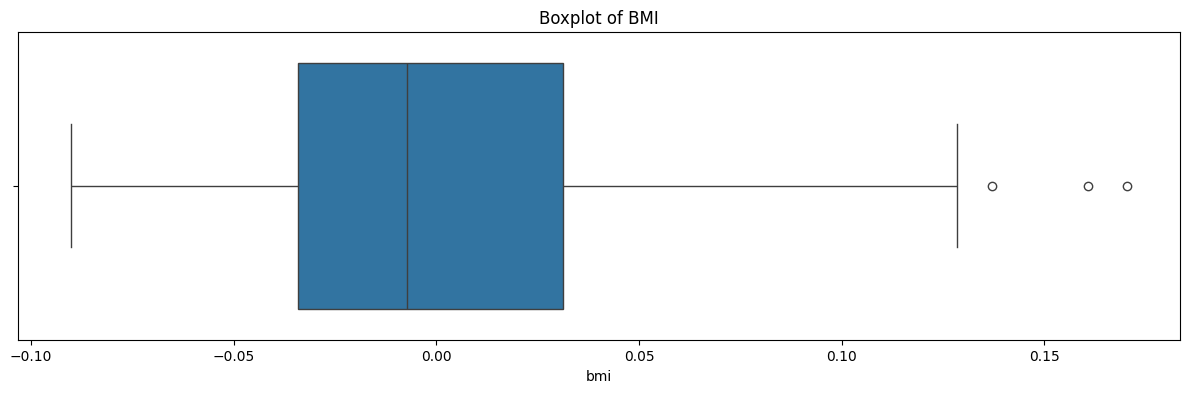

In [3]:
# Visualizing it in a boxplot for BMI column

plt.figure(figsize=(15, 4))
sns.boxplot(x=df_diabetics['bmi'])
plt.title('Boxplot of BMI')
plt.show()

- We can conclude that our BMI column has outliers based on the points appearing outside the box plot's whiskers.

### Removing the outliers from the BMI column

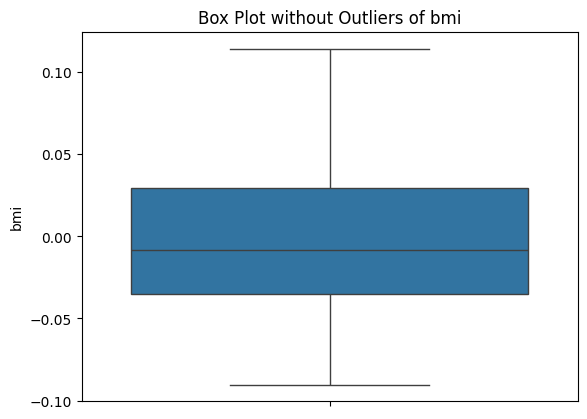

In [4]:
# Removing the outliers and replacing them with a predefined threshold.

# print(df_diabetics[df_diabetics['bmi'] <= 0.12])

def outlier_removal_boxplot(df, column, threshold):
    removed_outliers = df[df[column] <= threshold]

    sns.boxplot(removed_outliers[column])
    plt.title(f'Box Plot without Outliers of {column}')
    plt.show()
    return removed_outliers

threshold_value = 0.12

no_outliers = outlier_removal_boxplot(df_diabetics, 'bmi', threshold_value)


## Visualizing and Removing Outliers Using Scatter Plots

- Scatter plots help show the relationship between two variables.
- In a scatter plot, outliers appear as points that are far away from the main group of data points.


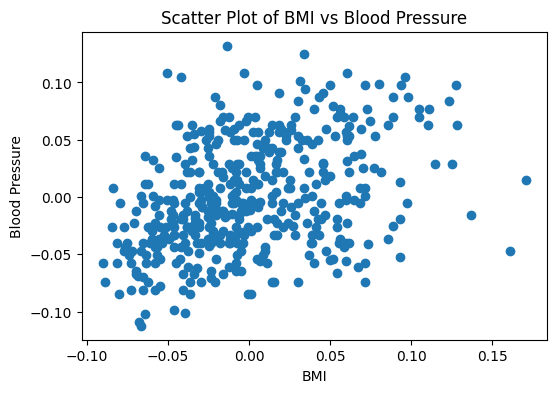

In [5]:
# Plotting a scatter plot

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df_diabetics['bmi'], df_diabetics['bp'])
ax.set_xlabel('BMI')
ax.set_ylabel('Blood Pressure')
plt.title('Scatter Plot of BMI vs Blood Pressure')
plt.show()

- Based on the output, we can conclude that the data points appearing in the top-right corner of the graph are potential outliers because they are far from the bottom-left corner, where most of the data points are clustered.

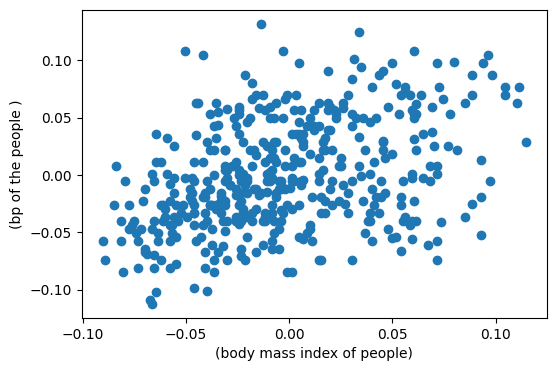

In [ ]:
# Removing or modifying outliers based on the standard BMI value of 0.12 and blood pressure (BP) value of 0.8.

outliers_indices = np.where((df_diabetics['bmi'] > 0.12) & (df_diabetics['bp'] < 0.8)) # finds out the indices in the dataframe where bmi is greater than 0.12 and bp is less than 0.8
# print(outliers_indices[0])

# droping rows that have bmi larger than the set standard and bp lower than .8

no_outliers1 = df_diabetics.drop(outliers_indices[0])
# print(no_outliers1)

# ploting scatter plot to visualizer our dataset after removing ourliers
fig, ax_no_outliers = plt.subplots(figsize=(6,4))
ax_no_outliers.scatter(no_outliers1['bmi'], no_outliers1['bp'])
ax_no_outliers.set_xlabel('(body mass index of people)')
ax_no_outliers.set_ylabel('(bp of the people )')
plt.show()

## Using Z-score methond to detect outliers
- Z-Score also known as standard score
- shows how far a data point is from the mean in terms of standard deviations
- If the Z-score is greater than a chosen threshold , the value is considered an outlier.

In [8]:
# check outliers in the age column

z = np.abs(stats.zscore(df_diabetics['age']))
print(z)

[0.80050009 0.03956713 1.79330681 1.87244107 0.11317236 1.94881082
 0.9560041  1.33508832 0.87686984 1.49059233 2.02518057 0.57139085
 0.34228161 0.11317236 0.95323959 1.1087436  0.11593688 1.48782782
 0.80326461 0.57415536 1.03237385 1.79607132 1.79607132 0.95323959
 1.33785284 1.41422259 2.25428981 0.49778562 1.10597908 1.41145807
 1.26148309 0.49778562 0.72413034 0.6477606  0.34228161 1.02960933
 0.26591186 0.19230663 0.03956713 0.03956713 0.11317236 2.10155031
 1.26148309 0.41865135 0.95323959 0.57139085 1.18511334 1.64333183
 1.41145807 0.87963435 0.72413034 1.25871858 1.1087436  0.19230663
 1.03237385 0.87963435 0.87963435 0.57415536 0.87686984 1.33508832
 1.49059233 0.87963435 0.57415536 0.72689486 1.41145807 0.9560041
 0.19230663 0.87686984 0.80050009 0.34228161 0.03956713 0.03956713
 1.33508832 0.26591186 0.26591186 0.19230663 0.65052511 2.02518057
 0.11317236 2.17792006 1.48782782 0.26591186 0.34504612 0.80326461
 0.03680262 0.95323959 1.49059233 0.95323959 1.1087436  0.95600

- After identifying outliers using the Z-score method, we can either trim them by removing them or cap them by replacing them with a predefined limit.

In [14]:
# trimming the outliers

# set a limit
threshold_z = 2

outliers_z = np.where(z > threshold_z)[0]
# print(outliers_z)

noz_outliers = df_diabetics.drop(outliers_z)
# noz_outliers

print("Original DataFrame Shape:", df_diabetics.shape)
print("DataFrame Shape after Removing Outliers:", noz_outliers.shape)

Original DataFrame Shape: (442, 10)
DataFrame Shape after Removing Outliers: (426, 10)


In [15]:
# capping the outliers

# create a copy of your dataset
df_capped = df_diabetics.copy()

df_capped['age'] = np.where(z > threshold_z, df_diabetics['age'].mean() + threshold_z * df_diabetics['age'].std(), df_diabetics['age'])

print("Original DataFrame Shape:", df_diabetics.shape)
print("DataFrame Shape after Capping Outliers:", df_capped.shape)

Original DataFrame Shape: (442, 10)
DataFrame Shape after Capping Outliers: (442, 10)


## indetifying Outliers using Interquartile Rang (IQR)
* common and reliable method
* works well when the data is skewed and indentifies extreme values using quartiles.
* IQR = third quartile(Q3) - first quartile(Q1)

In [22]:
# first quartile
# Q1 = np.percentile(df_diabetics['bmi'], 25, method='midpoint')
Q1 = df_diabetics['bmi'].quantile(0.25)

# third quartile
# Q3 = np.percentile(df_diabetics['bmi'], 75, method='midpoint')
Q3 = df_diabetics['bmi'].quantile(0.75)
IQR = Q3 - Q1

print("Q1 = ", Q1, "\nQ3 = ", Q3, "\nIQR = ", IQR)

Q1 =  -0.03422906805670789 
Q3 =  0.031248015431550695 
IQR =  0.06547708348825859


In [ ]:
# defining uper and lower bound using IQR to help indetify outliers
upper_bound = Q3 + 1.5 * IQR
# upper_array = np.array(df_diabetics['bmi'] >= upper_bound)[0]
upper_array = np.where(df_diabetics['bmi'] >= upper_bound)[0]
print("Upper: ", upper_bound)
# print("U_Array: ", upper_array)
# print("U_Array sum: ", upper_array.sum())

lower_bound = Q3 - 1.5 * IQR
# lower_array = np.array(df_diabetics['bmi'] <= lower_bound)[0]
lower_array = np.where(df_diabetics['bmi'] <= lower_bound)[0]
print("lower: ", lower_bound)
# print("L_Array: ", lower_array)
# print("L_Array sum: ", lower_array.sum())

Upper:  0.1294636406639386
U_Array sum:  989
lower:  -0.06696760980083719
L_Array sum:  4832


In [25]:
# removing outliers based on IQR
print("Old Shape: ", df_diabetics.shape)

df_diabetics.drop(index=upper_array, inplace=True)
df_diabetics.drop(index=lower_array, inplace=True)

print("New Shape: ", df_diabetics.shape)

Old Shape:  (442, 10)
New Shape:  (417, 10)


In [27]:
# Capping outliers

# copy of our dataset
df_capped1 = df_diabetics.copy()

df_capped1['bmi'] = np.where(df_capped1['bmi'] > upper_bound, upper_bound, df_capped1['bmi'])
df_capped1['bmi'] = np.where(df_capped1['bmi'] < lower_bound, lower_bound, df_capped1['bmi'])

print("Shape after Capping: ", df_capped1.shape)

Shape after Capping:  (417, 10)
